# STOFS-3D-Atlantic: explore the output and plot any variable with its mesh

This notebook has two parts:

**Part A: understand the data** (run once)
1. **Cycles:** which forecast runs exist for a day
2. **Forecast times:** how each run is split into files, and which valid times each file covers
3. **Variables:** what is 2D, what is 3D, and which file each variable lives in

**Part B: plot** (run as often as you like)
4. Helper functions (just run the cell)
5. **One cell where you type a variable name** (plus time, layer and region). It reads only your region from S3 and plots the field with the model mesh drawn on top.

Data source: the NOAA Open Data bucket `s3://noaa-nos-stofs3d-pds/STOFS-3D-Atl/`, read anonymously over the internet with no download step.

### Setup

Required packages: `xarray h5netcdf s3fs numpy pandas matplotlib`

In [1]:
# %pip install xarray h5netcdf s3fs numpy pandas matplotlib

import os, re
import numpy as np
import pandas as pd
import xarray as xr
import s3fs
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.collections import LineCollection, PolyCollection

# ZOOMABLE = True gives matplotlib figures a toolbar with zoom-box and pan buttons.
# It needs the ipympl package in BOTH the kernel and the JupyterLab environment.
# If figures don't appear (e.g. "Failed to load model class 'MPLCanvasModel'"), set it to False,
# restart the kernel, and use the Bokeh plot in section 6 for zooming instead.
ZOOMABLE = True

try:
    import ipympl  # noqa: F401
except ImportError:
    ZOOMABLE = False
if ZOOMABLE:
    %matplotlib widget
else:
    %matplotlib inline
print("Zoomable matplotlib figures:", ZOOMABLE)

BUCKET = "noaa-nos-stofs3d-pds"
fs = s3fs.S3FileSystem(anon=True)

DATE = "20261009"     # forecast day to explore, YYYYMMDD
CYCLE = "12"          # cycle hour; section 1 prints which ones exist for DATE

Zoomable matplotlib figures: True


---
## Part A: understand the data

## 1. Cycles

STOFS-3D-Atl is run on a schedule. Each run is called a **cycle** and is named by its start hour in UTC, e.g. `t12z` is the run that starts at 12:00 UTC. All files for one day are in one folder:

`STOFS-3D-Atl/stofs_3d_atl.YYYYMMDD/`

The gridded model output files are named

`stofs_3d_atl.t<CC>z.fields.<FIELD>_<SEGMENT>.nc`

| Part | Meaning |
|---|---|
| `t<CC>z` | cycle (start hour, UTC) |
| `<FIELD>` | which variables are in the file: `out2d` holds all 2D variables; each 3D variable has its own file (e.g. `temperature`, `salinity`), and `zCoordinates` holds the depth of each vertical layer |
| `<SEGMENT>` | which forecast hours the file covers, e.g. `f001_012` = hours 1 to 12 after the cycle start |

The cell below lists what actually exists for `DATE`.

In [2]:
folder = f"{BUCKET}/STOFS-3D-Atl/stofs_3d_atl.{DATE}/"
try:
    listing = fs.ls(folder, detail=True)
except Exception as e:
    print(f"Could not list {folder}: {e}")
    listing = []

pat = re.compile(r"stofs_3d_atl\.t(\d\d)z\.fields\.(\w+?)_([a-z]\d{3}_\d{3})\.nc$")
rows = []
for f in listing:
    m = pat.search(f["name"])
    if m:
        rows.append({"cycle": m.group(1), "field": m.group(2), "segment": m.group(3),
                     "size_MB": round(f["size"] / 1e6), "file": os.path.basename(f["name"])})
files = pd.DataFrame(rows, columns=["cycle", "field", "segment", "size_MB", "file"])

print(f"Folder: {folder}")
print(f"{len(listing)} objects, {len(files)} gridded field files")
print("Cycles available:", sorted(files.cycle.unique()))
if CYCLE not in set(files.cycle):
    print(f"Note: cycle t{CYCLE}z not found for {DATE}; change CYCLE in the setup cell.")

files.groupby("cycle").agg(n_files=("file", "size"),
                           fields=("field", lambda s: ", ".join(sorted(s.unique()))),
                           total_GB=("size_MB", lambda s: round(s.sum() / 1000, 1)))

Folder: noaa-nos-stofs3d-pds/STOFS-3D-Atl/stofs_3d_atl.20261009/
418 objects, 80 gridded field files
Cycles available: ['12']


,n_files,fields,total_GB
cycle,,,
12,80,"diffusivity, horizontalVelX, horizontalVelY, o...",141.3


## 2. Forecast times

One cycle is split into several files along time. Each **segment** covers a block of hours, and every field type uses the same segments. Inside each file the `time` coordinate gives the **valid time** (the moment the values apply to), usually hourly.

The table below opens one file per segment (only metadata is read, so this is fast) and shows:
- how many time steps the file has,
- the first and last valid time,
- the same thing as hours relative to the cycle start. Negative hours, if any, are nowcast/hindcast; positive hours are forecast.

In Part B you pick a segment, and then a **time index** within it (0 = its first time step).

In [3]:
_open_cache = {}

def open_file(field, segment, cycle=None, quiet=False):
    # Open one STOFS field file lazily (only metadata is read). Returns None on failure.
    cycle = cycle or CYCLE
    fname = f"stofs_3d_atl.t{cycle}z.fields.{field}_{segment}.nc"
    if fname not in _open_cache:
        try:
            _open_cache[fname] = xr.open_dataset(fs.open(folder + fname, "rb"), engine="h5netcdf")
        except Exception as e:
            if not quiet:
                print(f"Could not open {fname}: {type(e).__name__}: {e}")
            return None
    return _open_cache[fname]

cycle_files = files[files.cycle == CYCLE]
cycle_start = np.datetime64(f"{DATE[:4]}-{DATE[4:6]}-{DATE[6:]}T{CYCLE}:00")

time_rows = []
for seg, g in cycle_files.groupby("segment"):
    ds = open_file(g.field.iloc[0], seg)
    if ds is None or "time" not in ds.coords:
        continue
    t = ds["time"].values
    hrs = (t - cycle_start) / np.timedelta64(1, "h")
    time_rows.append({"segment": seg, "time steps": len(t),
                      "first valid (UTC)": np.datetime_as_string(t[0], unit="m"),
                      "last valid (UTC)": np.datetime_as_string(t[-1], unit="m"),
                      "hours from cycle start": f"{hrs[0]:+.0f} to {hrs[-1]:+.0f}"})
SEGMENTS = [r["segment"] for r in time_rows]
print(f"Cycle t{CYCLE}z started {np.datetime_as_string(cycle_start, unit='m')} UTC")
pd.DataFrame(time_rows)

Cycle t12z started 2026-10-09T12:00 UTC


,segment,time steps,first valid (UTC),last valid (UTC),hours from cycle start
0,f001_012,12,2026-10-09T13:00,2026-10-10T00:00,+1 to +12
1,f013_024,12,2026-10-10T01:00,2026-10-10T12:00,+13 to +24
2,f025_036,12,2026-10-10T13:00,2026-10-11T00:00,+25 to +36
3,f037_048,12,2026-10-11T01:00,2026-10-11T12:00,+37 to +48
4,f049_060,12,2026-10-11T13:00,2026-10-12T00:00,+49 to +60
5,f061_072,12,2026-10-12T01:00,2026-10-12T12:00,+61 to +72
6,f073_084,12,2026-10-12T13:00,2026-10-13T00:00,+73 to +84
7,f085_096,12,2026-10-13T01:00,2026-10-13T12:00,+85 to +96
8,n001_012,12,2026-10-08T13:00,2026-10-09T00:00,-23 to -12
9,n013_024,12,2026-10-09T01:00,2026-10-09T12:00,-11 to +0


## 3. Variables: 2D and 3D

STOFS-3D-Atl is built on the **SCHISM** model, which uses an **unstructured mesh**: about 3 million nodes connected into triangles and quads. Every output file carries the mesh description (node coordinates and the node lists of each element), so any one file is enough to draw the mesh.

- **2D variables** have one value per node per time step: `(time, node)`. Examples: water level (`elevation`), air pressure, wind, depth-averaged currents. They're all in the `out2d` file.
- **3D variables** also have a vertical dimension: `(time, node, layer)`. SCHISM has 49 layers, numbered **from the bottom (0) up to the surface (48)**. In shallow water a node uses fewer layers, and the unused ones near the bottom hold fill values. Each 3D variable has its own file.
- `zCoordinates` is the depth of every layer at every node and time. The layers stretch with the water column, so their depths change with the tide.

The table lists every time-varying variable with:
- **kind:** 2D or 3D
- **file:** the `<FIELD>` file it comes from
- **units** and **long_name:** taken from the file's attributes. Many STOFS files leave these empty, so missing ones are filled from standard SCHISM output definitions, and the **info from** column says which source was used.

Two **derived** variables are added when both components are available. They're computed on the fly as the magnitude of the X and Y components:
- `depthAverageSpeed` (2D)
- `horizontalSpeed` (3D)

X/Y components point east/north, because this grid uses longitude/latitude.

In [4]:
NODE = "nSCHISM_hgrid_node"
LOCATION = {"nSCHISM_hgrid_node": "node", "nSCHISM_hgrid_face": "element", "nSCHISM_hgrid_edge": "edge"}

# Standard SCHISM units/descriptions, used only when the file's attributes are empty
SCHISM_INFO = {
    "elevation":          ("m",        "water surface elevation"),
    "airPressure":        ("Pa",       "sea-level air pressure"),
    "windSpeedX":         ("m/s",      "eastward 10 m wind speed"),
    "windSpeedY":         ("m/s",      "northward 10 m wind speed"),
    "windStressX":        ("N/m2",     "eastward wind stress at the surface"),
    "windStressY":        ("N/m2",     "northward wind stress at the surface"),
    "depthAverageVelX":   ("m/s",      "eastward depth-averaged velocity"),
    "depthAverageVelY":   ("m/s",      "northward depth-averaged velocity"),
    "evaporationRate":    ("kg/m2/s",  "evaporation rate"),
    "precipitationRate":  ("kg/m2/s",  "precipitation rate"),
    "dryFlagNode":        ("1",        "dry flag at nodes (1 = dry, 0 = wet)"),
    "dryFlagElement":     ("1",        "dry flag at elements (1 = dry, 0 = wet)"),
    "dryFlagSide":        ("1",        "dry flag at edges (1 = dry, 0 = wet)"),
    "isolatedPondNode":   ("1",        "isolated pond flag at nodes"),
    "temperature":        ("degC",     "water temperature"),
    "salinity":           ("PSU",      "salinity"),
    "horizontalVelX":     ("m/s",      "eastward water velocity"),
    "horizontalVelY":     ("m/s",      "northward water velocity"),
    "verticalVelocity":   ("m/s",      "vertical water velocity (positive up)"),
    "diffusivity":        ("m2/s",     "vertical eddy diffusivity"),
    "viscosity":          ("m2/s",     "vertical eddy viscosity"),
    "turbulentKineticEner": ("m2/s2",  "turbulent kinetic energy"),
    "mixingLength":       ("m",        "turbulent mixing length"),
    "zCoordinates":       ("m",        "z (height) of each vertical layer, negative below datum"),
}
DERIVED = {"depthAverageSpeed": ("depthAverageVelX", "depthAverageVelY", "2D", "depth-averaged current speed"),
           "horizontalSpeed":   ("horizontalVelX",   "horizontalVelY",   "3D", "horizontal current speed")}

ref_seg = SEGMENTS[0] if SEGMENTS else None
VAR2FIELD, VAR_INFO, var_rows = {}, {}, []
for field in sorted(cycle_files.field.unique()):
    segs = sorted(cycle_files[cycle_files.field == field].segment)
    ds = open_file(field, ref_seg if ref_seg in segs else segs[0])
    if ds is None:
        continue
    for v, da in ds.data_vars.items():
        if "time" not in da.dims:
            continue          # static mesh/bathymetry info, not a field
        kind = "3D" if da.ndim == 3 else "2D"
        file_units, file_name = da.attrs.get("units", ""), da.attrs.get("long_name", "")
        dflt_units, dflt_name = SCHISM_INFO.get(v, ("", ""))
        units, long_name = file_units or dflt_units, file_name or dflt_name
        src = ("file" if file_units and file_name else
               "SCHISM default" if not (file_units or file_name) else "file + SCHISM default")
        if not (units or long_name):
            src = "unknown"
        VAR2FIELD[v] = field
        VAR_INFO[v] = dict(kind=kind, units=units, long_name=long_name,
                           on=next((LOCATION[d] for d in da.dims if d in LOCATION), "?"))
        var_rows.append({"variable": v, "kind": kind, "file": field, "units": units,
                         "long_name": long_name, "info from": src})

for name, (u, v, kind, desc) in DERIVED.items():
    if u in VAR2FIELD and v in VAR2FIELD:
        units = VAR_INFO[u]["units"] or "m/s"
        VAR2FIELD[name] = "derived"
        VAR_INFO[name] = dict(kind=kind, units=units, long_name=f"{desc}, sqrt({u}² + {v}²)", on="node")
        var_rows.append({"variable": name, "kind": kind, "file": f"derived ({u}, {v})", "units": units,
                         "long_name": VAR_INFO[name]["long_name"], "info from": "computed"})

variables = pd.DataFrame(var_rows, columns=["variable", "kind", "file", "units", "long_name", "info from"]) \
              .sort_values(["kind", "variable"], ignore_index=True)
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 80):
    display(variables)

,variable,kind,file,units,long_name,info from
0,airPressure,2D,out2d,Pa,sea-level air pressure,SCHISM default
1,depthAverageSpeed,2D,"derived (depthAverageVelX, depthAverageVelY)",m/s,"depth-averaged current speed, sqrt(depthAverageVelX² + depthAverageVelY²)",computed
2,depthAverageVelX,2D,out2d,m/s,eastward depth-averaged velocity,SCHISM default
3,depthAverageVelY,2D,out2d,m/s,northward depth-averaged velocity,SCHISM default
4,dryFlagElement,2D,out2d,1,"dry flag at elements (1 = dry, 0 = wet)",SCHISM default
5,dryFlagNode,2D,out2d,1,"dry flag at nodes (1 = dry, 0 = wet)",SCHISM default
6,dryFlagSide,2D,out2d,1,"dry flag at edges (1 = dry, 0 = wet)",SCHISM default
7,elevation,2D,out2d,m,water surface elevation above xgeoid20b,file
8,evaporationRate,2D,out2d,kg/m2/s,evaporation rate,SCHISM default
9,isolatedPondNode,2D,out2d,1,isolated pond node mask,file + SCHISM default


---
## Part B: plot

## 4. Helper functions

Just run this cell. It defines the functions that:
- cut the mesh down to your region (and remember it, so the next plot is instant),
- read **only your region's nodes** from S3 (a full 3D time step is about 600 MB, while a region is usually a few MB),
- plot the field with the mesh edges drawn on top, either with matplotlib (`plot_stofs`) or as an interactive Bokeh plot (`plot_stofs_bokeh`).

In [5]:
_region_cache = {}

def in_box(x, y, b):
    return (x >= b[0]) & (x <= b[1]) & (y >= b[2]) & (y <= b[3])

def get_region(ds, bbox):
    # Nodes, triangles and edges of the mesh inside bbox (cached per bbox)
    key = tuple(bbox)
    if key in _region_cache:
        return _region_cache[key]
    X = ds["SCHISM_hgrid_node_x"].values
    Y = ds["SCHISM_hgrid_node_y"].values
    node_idx = np.flatnonzero(in_box(X, Y, bbox))
    if node_idx.size == 0:
        print("No mesh nodes inside BBOX; check the box (lon_min, lon_max, lat_min, lat_max).")
        return None
    g2l = np.full(X.size, -1, dtype=np.int64)
    g2l[node_idx] = np.arange(node_idx.size)

    # elements -> triangles (quads split in two); read only the slice of the table we need
    fx, fy = ds["SCHISM_hgrid_face_x"].values, ds["SCHISM_hgrid_face_y"].values
    cand = np.flatnonzero(in_box(fx, fy, bbox))
    fn = ds["SCHISM_hgrid_face_nodes"][cand.min():cand.max() + 1].values[cand - cand.min()]
    start = int(ds["SCHISM_hgrid_face_nodes"].attrs.get("start_index", 1))
    valid = np.isfinite(fn) & (fn >= start)
    loc = np.where(valid, g2l[np.where(valid, fn - start, 0).astype(np.int64)], -1)
    quad = valid[:, 3]
    keep = (loc[:, :3] >= 0).all(axis=1) & (~quad | (loc[:, 3] >= 0))
    loc, quad = loc[keep], quad[keep]
    tris = np.vstack([loc[:, [0, 1, 2]], loc[quad][:, [0, 2, 3]]])

    # real elements: (n, 4) local node ids; for triangles the 4th entry repeats the 3rd
    faces = loc.copy()
    faces[~quad, 3] = faces[~quad, 2]

    # mesh edges = sides of the real elements, so quads stay quads (no diagonals)
    sides = [faces[:, [0, 1]], faces[:, [1, 2]], faces[quad][:, [2, 3]], faces[quad][:, [3, 0]],
             faces[~quad][:, [2, 0]]]
    edges = np.unique(np.sort(np.vstack(sides), axis=1), axis=0)

    # group region nodes into contiguous index blocks for efficient reads
    gaps = np.flatnonzero(np.diff(node_idx) > 50_000)
    starts, ends = np.r_[0, gaps + 1], np.r_[gaps + 1, node_idx.size]
    blocks = [(int(node_idx[a]), int(node_idx[b - 1]) + 1, a, b) for a, b in zip(starts, ends)]

    R = dict(node_idx=node_idx, x=X[node_idx], y=Y[node_idx], tris=tris, faces=faces, quad=quad,
             edges=edges, blocks=blocks)
    for name in ("bottom_index_node", "idmask", "depth"):
        if name in ds:
            R[name] = ds[name].values[node_idx]
    _region_cache[key] = R
    print(f"Region: {node_idx.size:,} nodes, {len(faces):,} elements "
          f"({int((~quad).sum()):,} triangles + {int(quad.sum()):,} quads), {len(edges):,} edges")
    return R

def read_region(da, t, R, layer_idx=None):
    # Values of da at time index t for region nodes; all layers if layer_idx is None
    lay = [d for d in da.dims if d not in ("time", NODE)]
    parts = []
    for a, b, s, e in R["blocks"]:
        sel = da.isel(time=t, **{NODE: slice(a, b)})
        if lay and layer_idx is not None:
            sel = sel.isel({lay[0]: layer_idx})
        parts.append(np.asarray(sel.values, dtype=float)[R["node_idx"][s:e] - a])
    return np.concatenate(parts, axis=0)

def report(F):
    good = F["vals"][np.isfinite(F["vals"])]
    if good.size:
        print(f"{F['variable']}: min {good.min():.3g}, mean {good.mean():.3g}, max {good.max():.3g} "
              f"{F['units']} over {good.size:,} wet nodes")
    else:
        print("All values are masked in this region/time/layer.")


def load_field(variable, segment=None, time_index=0, layer="surface", bbox=None, quiet=False):
    # Read one variable for the region. Returns a dict, or None (with a message) on any problem.
    if VAR2FIELD.get(variable) == "derived":
        u, v = DERIVED[variable][:2]
        Fu = load_field(u, segment, time_index, layer, bbox, quiet=True)
        Fv = load_field(v, segment, time_index, layer, bbox, quiet=True) if Fu else None
        if Fv is None:
            return None
        info = VAR_INFO[variable]
        F = dict(Fu, vals=np.hypot(Fu["vals"], Fv["vals"]), variable=variable,
                 units=info["units"], long_name=info["long_name"],
                 title=Fu["title"].replace(f"{u}: {VAR_INFO[u]['long_name']}",
                                           f"{variable}: {info['long_name'].split(',')[0]}", 1)
                                  .replace(f"[{Fu['units']}]", f"[{info['units']}]", 1)
                                  .replace(f"file: {VAR2FIELD[u]}", f"derived from {u}, {v}", 1))
        if not quiet:
            report(F)
        return F
    field = VAR2FIELD.get(variable)
    if field is None:
        print(f"'{variable}' not found. Choose one of:\n  " + ", ".join(sorted(VAR2FIELD)))
        return None
    segment = segment or ref_seg
    ds = open_file(field, segment)
    if ds is None:
        print(f"Segments available for {field}:",
              sorted(cycle_files[cycle_files.field == field].segment))
        return None
    da = ds[variable]
    if NODE not in da.dims:
        print(f"'{variable}' is defined on {[d for d in da.dims if d != 'time']}; only node variables can be plotted.")
        return None
    nt = ds.sizes["time"]
    if not 0 <= time_index < nt:
        print(f"time_index must be 0..{nt - 1} for segment {segment}")
        return None

    # mesh for the region (from this file, or any opened file that has it)
    mesh_ds = ds if "SCHISM_hgrid_face_nodes" in ds else next(
        (d for d in _open_cache.values() if "SCHISM_hgrid_face_nodes" in d), None)
    if mesh_ds is None:
        print("No opened file contains the mesh.")
        return None
    R = get_region(mesh_ds, bbox)
    if R is None:
        return None

    if da.ndim == 3:
        nlev = da.shape[da.dims.index([d for d in da.dims if d not in ("time", NODE)][0])]
        if layer == "surface":
            vals, lay_txt = read_region(da, time_index, R, nlev - 1), "surface layer"
        elif layer == "bottom":
            allv = read_region(da, time_index, R)                     # (node, layer)
            allv[np.abs(allv) >= 9999] = np.nan
            if "bottom_index_node" in R:
                kb = np.clip(R["bottom_index_node"].astype(int) - 1, 0, nlev - 1)
            else:                                                     # first valid value from the bottom
                kb = np.argmax(np.isfinite(allv), axis=1)
            vals, lay_txt = allv[np.arange(len(kb)), kb], "bottom layer"
        else:
            try:
                k = int(layer)
            except (TypeError, ValueError):
                k = -1
            if not 0 <= k < nlev:
                print(f"layer must be 'surface', 'bottom' or 0..{nlev - 1}")
                return None
            vals, lay_txt = read_region(da, time_index, R, k), f"layer {k} of 0..{nlev - 1}"
            if "bottom_index_node" in R:
                vals[k < R["bottom_index_node"].astype(int) - 1] = np.nan   # below the seabed
    else:
        vals, lay_txt = read_region(da, time_index, R), ""

    # mask fill values, masked nodes and dry nodes (when that info is in the file)
    vals[~np.isfinite(vals) | (np.abs(vals) >= 9999)] = np.nan
    if "idmask" in ds:
        vals[ds["idmask"].values[R["node_idx"]] == 1] = np.nan
    if "dryFlagNode" in ds:
        vals[read_region(ds["dryFlagNode"], time_index, R) > 0.5] = np.nan

    tval = ds["time"].values[time_index]
    fh = (tval - cycle_start) / np.timedelta64(1, "h")
    info = VAR_INFO.get(variable, {})
    units = info.get("units") or da.attrs.get("units", "")
    long_name = info.get("long_name") or da.attrs.get("long_name", "")
    kind = info.get("kind", "3D" if da.ndim == 3 else "2D")
    title = (f"{variable}: {long_name}" + (f" [{units}]" if units else "") +
             f" | {kind}" + (f", {lay_txt}" if lay_txt else "") + f", file: {field}" +
             f" | valid {np.datetime_as_string(tval, unit='m')} UTC (STOFS-3D-Atl t{CYCLE}z {DATE}, {fh:+.0f} h)")
    F = dict(R=R, vals=vals, variable=variable, units=units, long_name=long_name, title=title)
    if not quiet:
        report(F)
    return F


def edges_in_view(R, view):
    x, y, edges = R["x"], R["y"], R["edges"]
    mx = 0.5 * (x[edges[:, 0]] + x[edges[:, 1]])
    my = 0.5 * (y[edges[:, 0]] + y[edges[:, 1]])
    return edges[in_box(mx, my, view)]


def element_values(R, vals):
    # One value per real element (mean of its 3 or 4 nodes); NaN if any node is NaN
    f = R["faces"]
    v = vals[f]
    v[~R["quad"], 3] = v[~R["quad"], 2]          # triangles: 4th entry repeats the 3rd
    return v.mean(axis=1)


def plot_stofs(variable, segment=None, time_index=0, layer="surface", bbox=None, zoom=None,
               show_mesh=True, mesh_color="k", mesh_alpha=0.35, cmap="viridis", vmin=None, vmax=None,
               fill="elements"):
    # Matplotlib plot. With ZOOMABLE = True, use the toolbar's zoom-box / pan buttons.
    # fill="elements": one color per real element (quads kept as quads)
    # fill="smooth":   colors interpolated between nodes (drawn on triangles; mesh lines still show quads)
    F = load_field(variable, segment, time_index, layer, bbox)
    if F is None:
        return None
    R, vals = F["R"], F["vals"]
    x, y, tris = R["x"], R["y"], R["tris"]
    view = zoom or bbox

    tri = mtri.Triangulation(x, y, tris)
    tri.set_mask(np.isnan(vals)[tris].any(axis=1))
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.set_facecolor("0.85")                   # grey = land / masked / dry
    if np.isfinite(vals).any():
        # automatic limits from valid values only
        lo = np.nanmin(vals) if vmin is None else vmin
        hi = np.nanmax(vals) if vmax is None else vmax
        if fill == "smooth":
            pad = lo if np.isfinite(lo) else 0.0         # NaNs only sit under masked triangles
            pc = ax.tripcolor(tri, np.where(np.isnan(vals), pad, vals), shading="gouraud",
                              cmap=cmap, vmin=lo, vmax=hi)
        else:
            ev = element_values(R, vals)
            f = R["faces"]
            region = bbox if ZOOMABLE else view          # zoomable: draw all, so zooming out works
            cx, cy = x[f].mean(axis=1), y[f].mean(axis=1)
            use = np.isfinite(ev) & in_box(cx, cy, region)
            verts = np.stack([x[f[use]], y[f[use]]], axis=-1)   # (n, 4, 2); triangles repeat a vertex
            pc = PolyCollection(verts, array=ev[use], cmap=cmap, edgecolors="face", linewidths=0)
            pc.set_clim(lo, hi)
            ax.add_collection(pc)
        fig.colorbar(pc, ax=ax, shrink=0.7, label=f"{variable} [{F['units']}]" if F["units"] else variable)
    if show_mesh:
        # With a zoomable figure, draw every edge in BBOX so zooming in reveals them all
        e = edges_in_view(R, bbox if ZOOMABLE else view)
        segs = np.stack([np.c_[x[e[:, 0]], y[e[:, 0]]], np.c_[x[e[:, 1]], y[e[:, 1]]]], axis=1)
        n_view = len(edges_in_view(R, view))
        lw = 0.6 if n_view < 5_000 else 0.3 if n_view < 50_000 else 0.1
        ax.add_collection(LineCollection(segs, colors=mesh_color, linewidths=lw, alpha=mesh_alpha))
    ax.set_xlim(view[0], view[1]); ax.set_ylim(view[2], view[3])
    ax.set_aspect(1 / np.cos(np.deg2rad(np.mean(view[2:]))))
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_title(F["title"].replace(" | ", "\n"), fontsize=10)
    plt.show()
    return fig


def plot_stofs_bokeh(variable, segment=None, time_index=0, layer="surface", bbox=None, zoom=None,
                     show_mesh=True, mesh_color="black", mesh_alpha=0.4, cmap="viridis",
                     vmin=None, vmax=None, width=900, save_html=None, show_inline=True):
    # Interactive Bokeh plot: mouse-wheel zoom, drag to pan, hover readout.
    # Runs entirely in the browser; save_html="file.html" also writes a standalone page.
    try:
        from bokeh.plotting import figure, show, save
        from bokeh.io import output_notebook, output_file
        from bokeh.models import ColorBar, LinearColorMapper, HoverTool, ColumnDataSource
        from bokeh.resources import CDN
    except ImportError:
        print("bokeh is not installed: pip install bokeh")
        return None
    F = load_field(variable, segment, time_index, layer, bbox)
    if F is None:
        return None
    R, vals = F["R"], F["vals"]
    x, y, tris = R["x"], R["y"], R["tris"]
    view = zoom or bbox

    # real elements (triangles and quads) in view with a valid value, one color each
    f, q = R["faces"], R["quad"]
    ev = element_values(R, vals)
    use = in_box(x[f].mean(axis=1), y[f].mean(axis=1), view) & np.isfinite(ev)
    t, tq, tv = f[use], q[use], ev[use]
    e = edges_in_view(R, view) if show_mesh else np.empty((0, 2), int)
    n_shapes = len(t) + len(e)
    if n_shapes > 600_000:
        print(f"{len(t):,} elements and {len(e):,} edges in view: too much for a smooth browser plot. "
              f"Use a smaller ZOOM (or BBOX).")
        return None

    lo = np.nanmin(tv) if vmin is None else vmin
    hi = np.nanmax(tv) if vmax is None else vmax
    if not np.isfinite(lo) or hi <= lo:
        lo, hi = (0.0, 1.0) if not np.isfinite(lo) else (lo, lo + 1e-6)
    cm = plt.get_cmap(cmap)
    to_hex = lambda rgba: ["#%02x%02x%02x" % tuple(c) for c in (np.asarray(rgba)[:, :3] * 255).astype(int)]
    colors = to_hex(cm(np.clip((tv - lo) / (hi - lo), 0, 1)))
    palette = to_hex(cm(np.linspace(0, 1, 256)))

    lat0 = np.deg2rad(np.mean(view[2:]))
    height = int(width * (view[3] - view[2]) / ((view[1] - view[0]) * np.cos(lat0)))
    height = max(300, min(1400, height))
    p = figure(width=width, height=height, title=F["title"],
               x_range=(view[0], view[1]), y_range=(view[2], view[3]),
               tools="pan,wheel_zoom,box_zoom,reset,save", active_scroll="wheel_zoom",
               active_drag="pan", output_backend="webgl",
               x_axis_label="Longitude", y_axis_label="Latitude")
    p.background_fill_color = "#d9d9d9"
    xs_p = [list(x[r[:4] if qq else r[:3]]) for r, qq in zip(t, tq)]
    ys_p = [list(y[r[:4] if qq else r[:3]]) for r, qq in zip(t, tq)]
    src = ColumnDataSource(dict(xs=xs_p, ys=ys_p, c=colors, v=tv))
    tri_r = p.patches("xs", "ys", source=src, fill_color="c", line_color=None)
    p.add_tools(HoverTool(renderers=[tri_r], tooltips=[(variable, "@v{0.000}"), ("lon, lat", "$x{0.0000}, $y{0.0000}")]))
    if len(e):
        xs = np.full(3 * len(e), np.nan); ys = np.full(3 * len(e), np.nan)
        xs[0::3], xs[1::3] = x[e[:, 0]], x[e[:, 1]]
        ys[0::3], ys[1::3] = y[e[:, 0]], y[e[:, 1]]
        p.line(xs, ys, line_color=mesh_color, line_alpha=mesh_alpha,
               line_width=0.8 if len(e) < 20_000 else 0.4)
    p.add_layout(ColorBar(color_mapper=LinearColorMapper(palette=palette, low=lo, high=hi),
                          title=f"{variable} [{F['units']}]" if F["units"] else variable), "right")

    if save_html:
        output_file(save_html, title=F["title"])
        save(p, resources=CDN)
        print("Saved", os.path.abspath(save_html), "(download it and open in a web browser)")
    if show_inline:
        output_notebook(hide_banner=True)
        show(p)
    return p


print("Helpers ready. Variables you can plot:", ", ".join(sorted(VAR2FIELD)))

Helpers ready. Variables you can plot: airPressure, depthAverageSpeed, depthAverageVelX, depthAverageVelY, diffusivity, dryFlagElement, dryFlagNode, dryFlagSide, elevation, evaporationRate, horizontalSpeed, horizontalVelX, horizontalVelY, isolatedPondNode, precipitationRate, salinity, temperature, verticalVelocity, windSpeedX, windSpeedY, windStressX, windStressY, zCoordinates


## 5. Plot a variable

Edit the settings and run the cell. Change anything and run it again.

| Setting | What to put |
|---|---|
| `VARIABLE` | any name from the table in section 3, e.g. `"elevation"`, `"temperature"`, `"salinity"`, `"horizontalVelX"` |
| `SEGMENT` | a segment from section 2, e.g. `"f001_012"` |
| `TIME_INDEX` | time step within the segment, starting at `0` for the first. Section 2 shows how many steps each segment has |
| `LAYER` | 3D variables only: `"surface"`, `"bottom"`, or a number `0`–`48` (0 = bottom-most layer). Ignored for 2D variables |
| `BBOX` | region to read: `(lon_min, lon_max, lat_min, lat_max)` |
| `ZOOM` | `None` to show the whole BBOX, or a smaller box inside it to look closely at the mesh and data (no extra download) |
| `SHOW_MESH` | `True` to draw the mesh edges on top of the data. The lines follow the real elements, so quads appear as quads |
| `FILL` | `"elements"`: each triangle or quad gets one color, the mean of its nodes, so the real element shapes are visible. `"smooth"`: colors blend between nodes (drawn on triangles internally; the mesh lines still show the quads) |

Example regions:

| Region | BBOX |
|---|---|
| Chesapeake Bay | `(-77.5, -75.5, 36.5, 39.7)` |
| New York Harbor | `(-74.3, -73.6, 40.4, 40.95)` |
| Charleston, SC | `(-80.2, -79.6, 32.6, 33.0)` |
| Lower Mississippi / Barataria | `(-90.6, -89.0, 28.8, 30.2)` |

The first plot for a new region takes longer because the mesh is being cut. After that only the data is read.

**Zooming:** with `ZOOMABLE = True` (setup cell) the figure has a toolbar. Click the square **zoom** button and drag a box to zoom in, use the **arrows** button to pan, and use **home** to go back. All mesh edges in `BBOX` are drawn, so they become visible as you zoom in. 

Region: 232,339 nodes, 417,250 elements (384,510 triangles + 32,740 quads), 649,595 edges
salinity: min 0, mean 11.5, max 34.1 PSU over 232,339 wet nodes


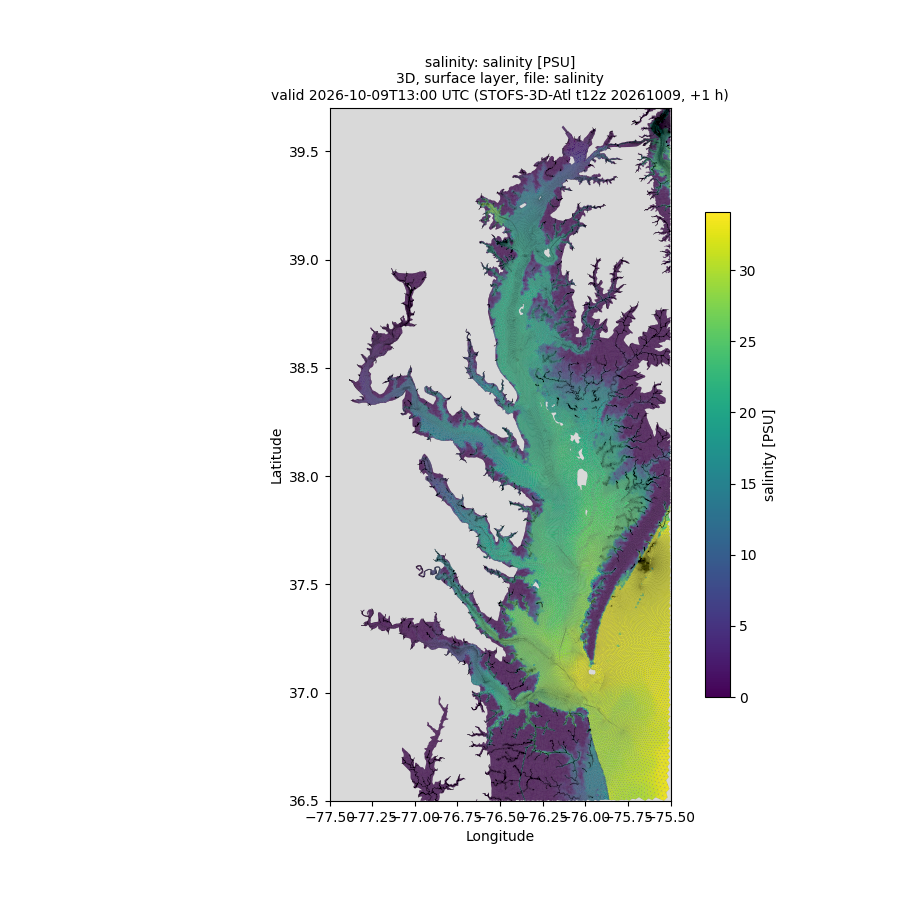

In [6]:
VARIABLE   = "salinity"
SEGMENT    = "f001_012"
TIME_INDEX = 0
LAYER      = "surface"        # "surface", "bottom", or 0..48  (3D only)
BBOX       = (-77.5, -75.5, 36.5, 39.7)   # Chesapeake Bay
ZOOM       = None             # e.g. (-76.5, -76.2, 36.9, 37.1) to look closely
SHOW_MESH  = True
FILL       = "elements"       # "elements": one color per triangle/quad (quads kept)
                              # "smooth":   colors interpolated between nodes
CMAP       = "viridis"        # e.g. "RdBu_r" for elevation or velocity
VMIN, VMAX = None, None       # color limits; None = automatic

fig = plot_stofs(VARIABLE, segment=SEGMENT, time_index=TIME_INDEX, layer=LAYER, bbox=BBOX,
                 zoom=ZOOM, show_mesh=SHOW_MESH, cmap=CMAP, vmin=VMIN, vmax=VMAX, fill=FILL)